# Plantilla genérica de valoración por DCF (FCFF)

Sirve para valorar cualquier empresa no financiera con el mismo método del modelo de ISA, en versión simple:

1. **Costo de capital:** CAPM con riesgo país y lambda, beta bottom-up re-apalancada con Hamada, Kd sintético y WACC en moneda local (Fisher).
2. **Proyección:** ingresos, EBIT, NOPAT, reinversión (capex − D&A + capital de trabajo), FCFF y ROIC.
3. **Valor terminal** con reinversión consistente: FCFF = NOPAT × (1 + g) × (1 − g / RONIC).
4. **Puente** de la firma al patrimonio y valor por acción.
5. **Chequeos de sensatez, sensibilidades y decisión.**

**Uso:** llene `data/plantilla_supuestos.csv` (supuestos escalares) y `data/plantilla_proyeccion.csv` (drivers año a año)
y corra todo. Los datos que vienen son de una empresa **ficticia** de ejemplo. Unidades: moneda local, millones de millones o la unidad que elija, de forma consistente.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('data') if Path('data').exists() else Path('../data')
sup = pd.read_csv(DATA / 'plantilla_supuestos.csv')
drivers = pd.read_csv(DATA / 'plantilla_proyeccion.csv', index_col='año')

S = {}
for k, v in zip(sup.clave, sup.valor):
    try:
        S[k] = float(v)
    except (TypeError, ValueError):
        S[k] = v
S = {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in S.items()}
display(sup)
display(drivers)

,clave,valor,unidad,descripcion
0,empresa,Empresa Ejemplo S.A.,texto,Nombre de la empresa (ejemplo ficticio: cámbie...
1,anio_base,2025,año,Último año con estados financieros reales
2,dias_a_cierre,62,días,Días entre la fecha de valoración y el cierre ...
3,precio,15000,moneda local,Precio de la acción en la fecha de valoración
4,acciones,500,millones,Acciones en circulación
5,ingresos_base,5000,moneda local mm,Ingresos del año base
6,capital_invertido_base,11500,moneda local mm,Deuda + patrimonio − caja − inversiones no ope...
7,treasury_10a,0.045,%,Bono del Tesoro de EE. UU. a 10 años
8,default_usa,0.0023,%,Diferencial de default de EE. UU. (Damodaran)
9,erp,0.0433,%,Prima de riesgo de mercado maduro (Damodaran)


,crecimiento_ingresos,margen_ebit,da_ingresos,capex_ingresos,ct_incremental
año,,,,,
2026,0.080,0.250,0.05,0.090,0.1
2027,0.075,0.255,0.05,0.088,0.1
2028,0.070,0.260,0.05,0.085,0.1
2029,0.065,0.260,0.05,0.082,0.1
2030,0.060,0.260,0.05,0.078,0.1
2031,0.055,0.260,0.05,0.075,0.1
2032,0.050,0.260,0.05,0.072,0.1
2033,0.047,0.260,0.05,0.070,0.1
2034,0.043,0.260,0.05,0.068,0.1


## 1. Costo de capital

In [2]:
def costo_capital(S, precio=None):
    rf_usd = S['treasury_10a'] - S['default_usa']
    fisher = (1 + S['pi_local']) / (1 + S['pi_usd'])
    patrimonio_mkt = (precio or S['precio']) * S['acciones'] / 1000 + S['minoritarios']
    d_e = S['deuda'] / patrimonio_mkt
    beta = S['beta_desapalancada'] * (1 + (1 - S['tasa_marginal']) * d_e)          # Hamada
    ke_usd = rf_usd + beta * S['erp'] + S['lambda'] * S['crp']
    ke = (1 + ke_usd) * fisher - 1
    kd = (1 + rf_usd + S['default_pais'] + S['spread_empresa']) * fisher - 1
    wd = S['deuda'] / (S['deuda'] + patrimonio_mkt)
    wacc = S['wacc_manual'] or (1 - wd) * ke + wd * kd * (1 - S['tasa_marginal'])
    return dict(rf_usd=rf_usd, beta=beta, d_e=d_e, ke_usd=ke_usd, ke=ke, kd=kd, wd=wd, wacc=wacc)

K = costo_capital(S)
pd.Series(K).to_frame('valor').style.format('{:.4f}')

,valor
rf_usd,0.0427
beta,1.0773
d_e,0.5333
ke_usd,0.1178
ke,0.1353
kd,0.0958
wd,0.3478
wacc,0.1099


## 2. Proyección del FCFF

In [3]:
def proyectar(S, drivers):
    P = drivers.copy()
    P['ingresos'] = S['ingresos_base'] * (1 + P.crecimiento_ingresos).cumprod()
    ing_prev = P.ingresos.shift(1).fillna(S['ingresos_base'])
    P['ebit'] = P.ingresos * P.margen_ebit
    P['nopat'] = P.ebit * (1 - S['tasa_efectiva'])
    P['capex'] = P.ingresos * P.capex_ingresos
    P['da'] = P.ingresos * P.da_ingresos
    P['delta_ct'] = (P.ingresos - ing_prev) * P.ct_incremental
    P['reinversion'] = P.capex - P.da + P.delta_ct
    P['fcff'] = P.nopat - P.reinversion
    P['capital_inicial'] = S['capital_invertido_base'] + P.reinversion.cumsum().shift(1).fillna(0)
    P['roic'] = P.nopat / P.capital_inicial
    P['tasa_reinversion'] = P.reinversion / P.nopat
    return P

P = proyectar(S, drivers)
P[['ingresos', 'ebit', 'nopat', 'reinversion', 'fcff', 'capital_inicial', 'roic', 'tasa_reinversion']].T.style.format('{:,.3f}')

año,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
ingresos,"5,400.000","5,805.000","6,211.350","6,615.088","7,011.993","7,397.653","7,767.535","8,132.609","8,482.312","8,821.604"
ebit,"1,350.000","1,480.275","1,614.951","1,719.923","1,823.118","1,923.390","2,019.559","2,114.478","2,205.401","2,293.617"
nopat,945.000,"1,036.193","1,130.466","1,203.946","1,276.183","1,346.373","1,413.691","1,480.135","1,543.781","1,605.532"
reinversion,256.000,261.090,258.032,252.057,236.026,223.507,207.874,199.160,187.652,175.075
fcff,689.000,775.103,872.433,951.889,"1,040.156","1,122.866","1,205.817","1,280.975","1,356.129","1,430.457"
capital_inicial,"11,500.000","11,756.000","12,017.090","12,275.122","12,527.179","12,763.205","12,986.712","13,194.586","13,393.746","13,581.398"
roic,0.082,0.088,0.094,0.098,0.102,0.105,0.109,0.112,0.115,0.118
tasa_reinversion,0.271,0.252,0.228,0.209,0.185,0.166,0.147,0.135,0.122,0.109


## 3-4. Valor terminal, valor de la firma y valor por acción

Los flujos se descuentan al cierre del año base y luego el valor se trae `dias_a_cierre` días al Ke hasta la fecha de valoración.

In [4]:
def valorar(S, drivers, wacc=None, g=None, detalle=False):
    K = costo_capital(S)
    w = wacc if wacc is not None else K['wacc']
    g = g if g is not None else S['g']
    P = proyectar(S, drivers)
    n = len(P)
    t = np.arange(1, n + 1)
    ronic = S['ronic'] or P.roic.iloc[-1]
    vt = P.nopat.iloc[-1] * (1 + g) * (1 - g / ronic) / (w - g)
    pv_fcff = (P.fcff.values / (1 + w) ** t).sum()
    pv_vt = vt / (1 + w) ** n
    ev = pv_fcff + pv_vt
    equity = ev + S['caja'] + S['inversiones_no_operativas'] - S['deuda'] - S['minoritarios']
    por_accion = equity / S['acciones'] * 1000 / (1 + K['ke']) ** (S['dias_a_cierre'] / 365)
    if not detalle:
        return por_accion
    return pd.Series({'VP FCFF': pv_fcff, 'VP valor terminal': pv_vt, 'Valor de la firma': ev,
                      '% valor terminal': pv_vt / ev, '(+) Caja': S['caja'], '(+) Inversiones no operativas': S['inversiones_no_operativas'],
                      '(−) Deuda': -S['deuda'], '(−) Minoritarios': -S['minoritarios'], 'Patrimonio': equity,
                      'RONIC': ronic, 'WACC': w, 'g': g, 'Valor por acción': por_accion})

res = valorar(S, drivers, detalle=True)
valor = res['Valor por acción']
print(f"{S['empresa']}: valor por acción {valor:,.0f} vs precio {S['precio']:,.0f} ({valor / S['precio'] - 1:+.1%})")
res.to_frame('valor').style.format('{:,.4f}')

Empresa Ejemplo S.A.: valor por acción 16,299 vs precio 15,000 (+8.7%)


,valor
VP FCFF,"5,905.8139"
VP valor terminal,"5,571.4818"
Valor de la firma,"11,477.2957"
% valor terminal,0.4854
(+) Caja,600.0000
(+) Inversiones no operativas,250.0000
(−) Deuda,"-4,000.0000"
(−) Minoritarios,-0.0000
Patrimonio,"8,327.2957"
RONIC,0.1182


## 5. Chequeos de sensatez

Reglas de Damodaran que el modelo debería cumplir. Si alguna falla, revise los supuestos antes de confiar en el valor.

In [5]:
g, w, ronic = res['g'], res['WACC'], res['RONIC']
checks = pd.DataFrame([
    ('g < WACC', g < w, f'g {g:.2%} vs WACC {w:.2%}'),
    ('g real ≤ ~2% (no crece más que la economía)', (1 + g) / (1 + S['pi_local']) - 1 <= 0.02, f"g real {(1 + g) / (1 + S['pi_local']) - 1:.2%}"),
    ('RONIC cerca del WACC en madurez (± 3pp)', abs(ronic - w) <= 0.03, f'RONIC {ronic:.2%} vs WACC {w:.2%}'),
    ('Valor terminal < 80% del valor', res['% valor terminal'] < 0.8, f"{res['% valor terminal']:.1%}"),
    ('Crecimiento del último año ≈ g (± 1,5pp)', abs(drivers.crecimiento_ingresos.iloc[-1] - g) <= 0.015,
     f'{drivers.crecimiento_ingresos.iloc[-1]:.2%} vs {g:.2%}'),
    ('Capex ≥ D&A en el último año', P.capex.iloc[-1] >= P.da.iloc[-1], f'{P.capex.iloc[-1]:,.0f} vs {P.da.iloc[-1]:,.0f}'),
], columns=['chequeo', 'cumple', 'detalle'])
checks

,chequeo,cumple,detalle
0,g < WACC,True,g 4.00% vs WACC 10.99%
1,g real ≤ ~2% (no crece más que la economía),True,g real 0.00%
2,RONIC cerca del WACC en madurez (± 3pp),True,RONIC 11.82% vs WACC 10.99%
3,Valor terminal < 80% del valor,True,48.5%
4,"Crecimiento del último año ≈ g (± 1,5pp)",True,4.00% vs 4.00%
5,Capex ≥ D&A en el último año,True,582 vs 441


## 6. Sensibilidades

In [6]:
waccs = w + np.arange(-0.02, 0.0201, 0.005)
gs = g + np.arange(-0.01, 0.0101, 0.005)
sens = pd.DataFrame([[valorar(S, drivers, wacc=x, g=y) for y in gs] for x in waccs],
                    index=[f'WACC {x:.2%}' for x in waccs], columns=[f'g {y:.1%}' for y in gs])
sens.style.format('{:,.0f}').background_gradient(cmap='RdYlGn', axis=None)

,g 3.0%,g 3.5%,g 4.0%,g 4.5%,g 5.0%
WACC 8.99%,"23,631","24,215","24,904","25,735","26,759"
WACC 9.49%,"21,301","21,707","22,177","22,731","23,397"
WACC 9.99%,"19,302","19,581","19,898","20,264","20,692"
WACC 10.49%,"17,568","17,755","17,963","18,198","18,466"
WACC 10.99%,"16,051","16,170","16,299","16,442","16,600"
WACC 11.49%,"14,711","14,780","14,853","14,929","15,010"
WACC 11.99%,"13,519","13,551","13,582","13,612","13,639"
WACC 12.49%,"12,452","12,457","12,458","12,453","12,443"
WACC 12.99%,"11,492","11,476","11,455","11,426","11,389"


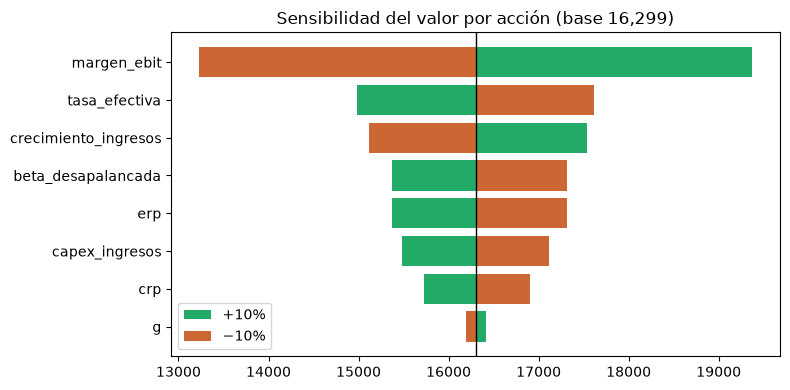

In [7]:
# Tornado: cada supuesto se mueve ±10% (relativo) dejando lo demás igual
def con(cambios_S=None, col=None, factor=1.0):
    S2, D2 = dict(S), drivers.copy()
    for k, v in (cambios_S or {}).items():
        S2[k] = v
    if col:
        D2[col] = D2[col] * factor
    return valorar(S2, D2)

tornado = {}
for k in ['erp', 'crp', 'beta_desapalancada', 'g', 'tasa_efectiva']:
    tornado[k] = (con({k: S[k] * 0.9}), con({k: S[k] * 1.1}))
for col in ['crecimiento_ingresos', 'margen_ebit', 'capex_ingresos']:
    tornado[col] = (con(col=col, factor=0.9), con(col=col, factor=1.1))
T = pd.DataFrame(tornado, index=['−10%', '+10%']).T
T['rango'] = (T['+10%'] - T['−10%']).abs()
T = T.sort_values('rango')

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(T.index, T['+10%'] - valor, left=valor, color='#2a6', label='+10%')
ax.barh(T.index, T['−10%'] - valor, left=valor, color='#c63', label='−10%')
ax.axvline(valor, color='k', lw=1)
ax.set_title(f'Sensibilidad del valor por acción (base {valor:,.0f})')
ax.legend(); plt.tight_layout(); plt.show()

## 7. Decisión y qué tiene que creer el mercado

In [8]:
def biseccion(f, a, b, n=200):
    if f(a) * f(b) > 0:
        return None          # ningún valor del rango iguala el precio
    for _ in range(n):
        c = (a + b) / 2
        a, b = (c, b) if f(a) * f(c) > 0 else (a, c)
    return (a + b) / 2

wacc_impl = biseccion(lambda x: valorar(S, drivers, wacc=x) - S['precio'], g + 0.005, 0.30)
g_impl = biseccion(lambda y: valorar(S, drivers, g=y) - S['precio'], -0.02, w - 0.002)
margen = valor / S['precio'] - 1
reco = 'COMPRAR' if margen > 0.15 else 'VENDER' if margen < -0.15 else 'MANTENER'
pd.Series({'Valor por acción': f'{valor:,.0f}', 'Precio': f"{S['precio']:,.0f}", 'Margen de seguridad': f'{margen:+.1%}',
           'WACC implícito en el precio': f'{wacc_impl:.2%}' if wacc_impl else 'ninguno en el rango',
           'g implícito en el precio': f'{g_impl:.2%}' if g_impl is not None else 'ninguno en el rango probado',
           'Recomendación (umbral ±15%)': reco})

Valor por acción                                    16,299
Precio                                              15,000
Margen de seguridad                                  +8.7%
WACC implícito en el precio                         11.44%
g implícito en el precio       ninguno en el rango probado
Recomendación (umbral ±15%)                       MANTENER
dtype: str